<a href="https://colab.research.google.com/github/Lagnajit09/100x_AI_ML/blob/main/calibrated-typed-decision/TrainACalibratedModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **[1] — Install**

In [1]:
!pip install -q -U "transformers>=4.48" datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 11.6 MB/s eta 0:00:00


## **[2] — Imports and GPU check**

In [2]:
import os, json, math, random, time, pickle
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import transformers
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__, "| transformers", transformers.__version__)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU found: Runtime > Change runtime type > T4 GPU")

device: cpu | torch 2.11.0+cpu | transformers 5.20.1
No GPU found: Runtime > Change runtime type > T4 GPU


## **[3] — Google Drive**

In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## **[4] — Settings**

In [4]:
SMOKE = False    # True: tiny practice run (a few minutes). False: the real experiment.
SEED  = 2        # Step 2: train with SEED = 1, then SEED = 2. Seed 0 is the run you already have.

MODEL_NAME   = "answerdotai/ModernBERT-base"
DATASET_NAME = "m-lagnajit/calibrated-typed-decisions"
DATASET_REV  = "main"           # v2. v1 is still available as revision="v1.0"
# A NEW folder: the v1 folder holds finished v1 runs, which Cell 15 would otherwise load
BASE_DIR = "/content/drive/MyDrive/ctd_student_v2_smoke" if SMOKE else "/content/drive/MyDrive/ctd_student_v2"
OUT_DIR  = BASE_DIR if SEED == 0 else f"{BASE_DIR}/seed{SEED}"    # seed 0 stays exactly where it was
os.makedirs(OUT_DIR, exist_ok=True)
SEEDS_ALL = [0, 1, 2]

RUNS = ["A", "B", "C", "D", "E"]
# A: right answers only            B: right answers, softened evenly
# C: the dataset's soft_label      D: a blend of A and C
# E: C, corrected wherever the teacher's top pick was wrong

# Step 2: building the input
MAX_LEN        = 512            # longest sequence the student reads
MAX_Q_TOKENS   = 96             # v2: yes/no questions carry a description, PubMedQA a research question
MAX_OPT_TOKENS = 32             # v2: each option is "label: description"

# Step 6: training
BATCH_SIZE   = 16
EPOCHS       = 1 if SMOKE else 3
LR_BODY      = 3e-5             # small, careful steps for the pre-trained body
LR_HEAD      = 1e-3             # bigger steps for the brand-new scorer
WEIGHT_DECAY = 0.01
WARMUP_FRAC  = 0.10
CLIP_NORM    = 1.0
SMOOTHING    = 0.1              # Run B: how much belief to spread evenly
BLEND        = 0.5              # Run D: share of the target given to the human answer
USE_AMP      = True             # 16-bit math on the GPU; set False if the loss turns NaN
SAVE_WEIGHTS = (not SMOKE) and SEED == 0   # ~600 MB each; seeds 1-2 keep predictions only

# Step 7: evaluation
N_BINS       = 10
N_BOOT       = 1000
MIN_FIT_ROWS = 30
DIAL_SETUP   = "2 dials"        # Step 1's decision. "12 dials" = one per source and type (the old setup)
SMOKE_SIZES  = {"train": 160, "validation": 80, "test": 80, "heldout": 40}

def amp_on():
    return USE_AMP and device == "cuda"

## **[5] — Load your dataset**

In [5]:
ds = load_dataset(DATASET_NAME, revision=DATASET_REV)
print(ds)
assert "heldout" in ds and "soft_label" in ds["train"].column_names, "this notebook needs v2 of the dataset"

def take(split):
    rows = list(ds[split])
    if SMOKE:
        rows = random.Random(SEED).sample(rows, min(SMOKE_SIZES[split], len(rows)))
    return rows

DATA = {split: take(split) for split in ["train", "validation", "test", "heldout"]}
print({split: len(rows) for split, rows in DATA.items()})
print(pd.DataFrame(DATA["train"]).groupby(["source", "type"]).size())
print("\ntraining targets come from:", pd.Series([r["soft_label_source"] for r in DATA["train"]]).value_counts().to_dict())

r = next(r for r in DATA["train"] if r["type"] == "choice")
print(json.dumps({k: r[k] for k in ["source", "type", "instructions", "state", "options",
                                    "option_descriptions", "gold", "soft_label", "soft_label_source"]},
                 indent=2, ensure_ascii=False)[:1400])

README.md:   0%|          | 0.00/8.54k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 8.15MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  889kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/16995 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1799 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1797 [00:00<?, ? examples/s]

Generating heldout split:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'source', 'source_license', 'source_id', 'type', 'instructions', 'state', 'options', 'option_descriptions', 'candidate', 'gold', 'gold_index', 'display_perm', 'teacher_option_logprobs', 'teacher_temperature', 'teacher_shift', 'teacher_probs', 'teacher_letter_mass', 'human_probs', 'soft_label', 'soft_label_source', 'corrected_soft_label', 'soft_label_corrected'],
        num_rows: 16995
    })
    validation: Dataset({
        features: ['id', 'source', 'source_license', 'source_id', 'type', 'instructions', 'state', 'options', 'option_descriptions', 'candidate', 'gold', 'gold_index', 'display_perm', 'teacher_option_logprobs', 'teacher_temperature', 'teacher_shift', 'teacher_probs', 'teacher_letter_mass', 'human_probs', 'soft_label', 'soft_label_source', 'corrected_soft_label', 'soft_label_corrected'],
        num_rows: 1799
    })
    test: Dataset({
        features: ['id', 'source', 'source_license', 'source_id', 'type', 'ins

## **[6] — Tokenizer and special tokens**

In [38]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
CLS, SEP, MASK, PAD = tok.cls_token_id, tok.sep_token_id, tok.mask_token_id, tok.pad_token_id
print({"[CLS]": CLS, "[SEP]": SEP, "[MASK]": MASK, "[PAD]": PAD})
assert None not in (CLS, SEP, MASK, PAD), "tokenizer is missing a special token"

{'[CLS]': 50281, '[SEP]': 50282, '[MASK]': 50284, '[PAD]': 50283}


## **[7] — Tokenize every piece once**

In [39]:
def option_texts(row):
    """What the student reads for each option, in stored order. v2: 'label: description'."""
    if row["type"] == "noul":
        return ["no", "yes"]
    descs = row.get("option_descriptions") or [""] * len(row["options"])
    return [f"{o}: {d}" if d else o for o, d in zip(row["options"], descs)]

def pretokenize(rows):
    qs   = tok([r["instructions"] for r in rows], add_special_tokens=False)["input_ids"]
    txts = tok([" " + r["state"] for r in rows], add_special_tokens=False)["input_ids"]
    flat = [" " + o for r in rows for o in option_texts(r)]
    flat_ids = tok(flat, add_special_tokens=False)["input_ids"]
    k = 0
    for r, q, t in zip(rows, qs, txts):
        n = len(option_texts(r))
        r["q_ids"]   = q[:MAX_Q_TOKENS]
        r["opt_ids"] = [o[:MAX_OPT_TOKENS] for o in flat_ids[k:k + n]]
        r["txt_ids"] = t
        k += n

for split in DATA:
    pretokenize(DATA[split])

r = next(r for r in DATA["train"] if r["type"] == "choice")
print("question pieces:", tok.convert_ids_to_tokens(r["q_ids"]))
print("option pieces:  ", [tok.convert_ids_to_tokens(o) for o in r["opt_ids"]])

# How much room is left for the text, in the worst row of every split?
head = max(2 + len(r["q_ids"]) + sum(1 + len(o) for o in r["opt_ids"]) + 1
           for split in DATA for r in DATA[split])
print(f"longest question + options: {head} tokens -> the text always keeps at least {MAX_LEN - head}")

question pieces: ['Which', 'Ġintent', 'Ġbest', 'Ġdescribes', 'Ġthis', 'Ġrequest', 'Ġto', 'Ġa', 'Ġvirtual', 'Ġassistant', '?']
option pieces:   [['Ġmeeting', 'Ġschedule', ':', 'Ġasking', 'Ġabout', 'Ġscheduled', 'Ġmeetings', 'Ġand', 'Ġtheir', 'Ġtim', 'ings'], ['Ġroll', 'over', 'Ġ401', 'k', ':', 'Ġroll', 'over', 'Ġof', 'Ġ401', 'k', 'Ġfunds'], ['Ġtaxes', ':', 'Ġasking', 'Ġabout', 'Ġtax', 'Ġpayments', 'Ġand', 'Ġobligations'], ['Ġspending', 'Ġhistory', ':', 'Ġasking', 'Ġabout', 'Ġpast', 'Ġspending'], ['Ġaccount', 'Ġblocked', ':', 'Ġaccount', 'Ġaccess', 'Ġor', 'Ġtransaction', 'Ġfunctionality', 'Ġrestricted'], ['Ġrestaurant', 'Ġsuggestion', ':', 'Ġsuggestions', 'Ġfor', 'Ġrestaurants']]
longest question + options: 122 tokens -> the text always keeps at least 390


## **[8] — Build one input sequence**

In [40]:
def build_input(row, rng=None):
    """[CLS] question [SEP] [MASK] opt [MASK] opt ... [SEP] text [SEP]
    rng=None -> options in stored order (evaluation)
    rng      -> options in a random order (training), so position can't become a shortcut"""
    n = len(row["opt_ids"])
    perm = list(range(n))
    if rng is not None:
        rng.shuffle(perm)                  # shown slot d holds stored option perm[d]
    ids = [CLS] + row["q_ids"] + [SEP]
    marker_pos = []
    for c in perm:
        marker_pos.append(len(ids))        # this option's [MASK] lands here
        ids += [MASK] + row["opt_ids"][c]
    ids += [SEP]
    room = MAX_LEN - len(ids) - 1          # leave space for the final [SEP]
    ids += row["txt_ids"][:room] + [SEP]   # only the text can ever be cut
    return {"input_ids": ids, "marker_pos": marker_pos, "perm": perm}

ex = build_input(DATA["train"][0])
print(len(ex["input_ids"]), "tokens | markers at", ex["marker_pos"])
for p, piece in enumerate(tok.convert_ids_to_tokens(ex["input_ids"])[:40]):
    print(f"{p:3d}  {piece}{'   <- marker' if p in ex['marker_pos'] else ''}")

81 tokens | markers at [13, 25, 37, 46, 54, 64]
  0  [CLS]
  1  Which
  2  Ġintent
  3  Ġbest
  4  Ġdescribes
  5  Ġthis
  6  Ġrequest
  7  Ġto
  8  Ġa
  9  Ġvirtual
 10  Ġassistant
 11  ?
 12  [SEP]
 13  [MASK]   <- marker
 14  Ġmeeting
 15  Ġschedule
 16  :
 17  Ġasking
 18  Ġabout
 19  Ġscheduled
 20  Ġmeetings
 21  Ġand
 22  Ġtheir
 23  Ġtim
 24  ings
 25  [MASK]   <- marker
 26  Ġroll
 27  over
 28  Ġ401
 29  k
 30  :
 31  Ġroll
 32  over
 33  Ġof
 34  Ġ401
 35  k
 36  Ġfunds
 37  [MASK]   <- marker
 38  Ġtaxes
 39  :


## **[9] — Each run’s target**

In [41]:
def make_target(row, run):
    """The run's target, in stored order."""
    n, g = len(row["opt_ids"]), row["gold_index"]
    onehot = np.zeros(n)
    onehot[g] = 1.0
    if run == "A":                                   # 100% on the right answer
        return onehot
    if run == "B":                                   # 0.9 + 0.1/n on the right answer, 0.1/n elsewhere
        t = np.full(n, SMOOTHING / n)
        t[g] += 1.0 - SMOOTHING
        return t
    soft = np.array(row["soft_label"], dtype=float)  # rater votes (GoEmotions) or calibrated teacher
    soft = soft / soft.sum()
    if run == "C":
        return soft
    if run == "D":                                   # part human answer, part soft label
        return BLEND * onehot + (1 - BLEND) * soft
    if run == "E":                                   # fix the teacher's wrong top picks, keep its shape
        if row["soft_label_source"] == "teacher":
            k = int(soft.argmax())
            if k != g:
                soft[k], soft[g] = soft[g], soft[k]  # the right answer gets the teacher's top value
        return soft
    raise ValueError(run)

# Show all five on a row where the teacher's top pick was wrong
wrong = [r for r in DATA["train"]
         if r["soft_label_source"] == "teacher" and int(np.argmax(r["soft_label"])) != r["gold_index"]]
r = wrong[0] if wrong else DATA["train"][0]
print("options:", option_texts(r), "\nright answer:", r["gold"])
for run in RUNS:
    print(f"target {run}:", np.round(make_target(r, run), 3))
teacher_rows = sum(r["soft_label_source"] == "teacher" for r in DATA["train"])
print(f"\nRun E changes {len(wrong)} of {teacher_rows} teacher-labelled training rows "
      f"({len(wrong) / max(1, teacher_rows):.1%}); rater-labelled GoEmotions rows are left as they are")

options: ['timezone: time zones of locations around the world', 'pay bill: request to pay a bill', "change user name: change user's name in system settings", 'date: request for current or future dates', 'travel alert: travel advisories and safety warnings', 'directions: requests for travel or location directions', 'traffic: traffic conditions and forecasts', 'distance: distance travel time estimates'] 
right answer: distance
target A: [0. 0. 0. 0. 0. 0. 0. 1.]
target B: [0.012 0.012 0.012 0.012 0.012 0.012 0.012 0.912]
target C: [0.001 0.001 0.001 0.001 0.002 0.772 0.005 0.216]
target D: [0.001 0.001 0.001 0.001 0.001 0.386 0.002 0.608]
target E: [0.001 0.001 0.001 0.001 0.002 0.216 0.005 0.772]

Run E changes 1391 of 13996 teacher-labelled training rows (9.9%); rater-labelled GoEmotions rows are left as they are


## **[10] — Build a batch**

In [42]:
def make_batch(rows, run=None, rng=None):
    items = [build_input(r, rng) for r in rows]
    B = len(rows)
    L = max(len(it["input_ids"]) for it in items)       # longest sequence in this batch
    K = max(len(it["marker_pos"]) for it in items)      # most options in this batch
    input_ids   = torch.full((B, L), PAD, dtype=torch.long)
    attn        = torch.zeros((B, L), dtype=torch.long)
    marker_pos  = torch.zeros((B, K), dtype=torch.long) # empty slots point at position 0
    option_mask = torch.zeros((B, K), dtype=torch.bool)
    target      = torch.zeros((B, K), dtype=torch.float)
    perms = []
    for b, (row, it) in enumerate(zip(rows, items)):
        n_tok, k = len(it["input_ids"]), len(it["marker_pos"])
        input_ids[b, :n_tok] = torch.tensor(it["input_ids"])
        attn[b, :n_tok] = 1
        marker_pos[b, :k] = torch.tensor(it["marker_pos"])
        option_mask[b, :k] = True
        if run is not None:
            t = make_target(row, run)
            target[b, :k] = torch.tensor(t[it["perm"]], dtype=torch.float)   # into shown order
        perms.append(it["perm"])
    return {"input_ids": input_ids, "attention_mask": attn, "marker_pos": marker_pos,
            "option_mask": option_mask, "target": target, "perms": perms}

demo = make_batch(DATA["train"][:8], run="C", rng=random.Random(0))
for k, v in demo.items():
    if torch.is_tensor(v):
        print(f"{k:15s} shape {tuple(v.shape)}")
print("option_mask:\n", demo["option_mask"].int())

input_ids       shape (8, 102)
attention_mask  shape (8, 102)
marker_pos      shape (8, 8)
option_mask     shape (8, 8)
target          shape (8, 8)
option_mask:
 tensor([[1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0, 0, 0, 0]], dtype=torch.int32)


## **[11] — The student**

In [43]:
MODEL_INPUTS = ["input_ids", "attention_mask", "marker_pos", "option_mask"]

class Student(nn.Module):
    def __init__(self, name):
        super().__init__()
        try:
            self.body = AutoModel.from_pretrained(name, reference_compile=False)
        except (TypeError, ValueError):
            self.body = AutoModel.from_pretrained(name)
        self.body = self.body.float()
        self.scorer = nn.Linear(self.body.config.hidden_size, 1)        # 768 weights + 1 bias

    def forward(self, input_ids, attention_mask, marker_pos, option_mask):
        h = self.body(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state  # (B, L, 768)
        idx = marker_pos.unsqueeze(-1).expand(-1, -1, h.size(-1))                           # (B, K, 768)
        markers = torch.gather(h, 1, idx)                                                   # (B, K, 768)
        scores = self.scorer(markers).squeeze(-1)                                           # (B, K)
        return scores.masked_fill(~option_mask, float("-inf"))                              # block empty slots

torch.manual_seed(SEED)
_student = Student(MODEL_NAME)
print(f"body:   {sum(p.numel() for p in _student.body.parameters()):,} numbers")
print(f"scorer: {sum(p.numel() for p in _student.scorer.parameters()):,} numbers")
with torch.no_grad():
    s = _student(**{k: demo[k] for k in MODEL_INPUTS})
print("scores shape:", tuple(s.shape))
print("untrained chances, row 0:", torch.softmax(s[0], dim=-1).numpy().round(3))
del _student

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


body:   149,014,272 numbers
scorer: 769 numbers
scores shape: (8, 8)
untrained chances, row 0: [0.184 0.17  0.181 0.152 0.159 0.154 0.    0.   ]


## **[12] — The loss**

In [44]:
def soft_cross_entropy(scores, target, option_mask):
    log_p = torch.log_softmax(scores.float(), dim=-1)
    log_p = log_p.masked_fill(~option_mask, 0.0)        # empty slots count as 0, not 0 × (−∞)
    return -(target * log_p).sum(dim=-1).mean()

# Check against Step 5's worked example
s = torch.tensor([[0.12, 2.35, 1.06, 0.06]])
m = torch.ones(1, 4, dtype=torch.bool)
for run, t in [("A", [0, 1, 0, 0]), ("B", [0.025, 0.925, 0.025, 0.025]), ("C", [0.08, 0.68, 0.18, 0.06])]:
    print(run, round(soft_cross_entropy(s, torch.tensor([t], dtype=torch.float), m).item(), 3))

A 0.395
B 0.54
C 0.943


## **[13] — Predicting and measuring**

In [6]:
@torch.no_grad()
def predict_scores(model, rows, bs=64):
    """Raw scores for every row, in stored order: one numpy array per row."""
    model.eval()
    out = []
    for i in range(0, len(rows), bs):
        batch = make_batch(rows[i:i + bs])                     # no rng: stored order
        feed = {k: batch[k].to(device) for k in MODEL_INPUTS}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_on()):
            s = model(**feed).float().cpu().numpy()
        for b, perm in enumerate(batch["perms"]):
            row_scores = np.empty(len(perm))
            row_scores[perm] = s[b, :len(perm)]                # shown order -> stored order
            out.append(row_scores)
    model.train()
    return out

def softmax_np(z):
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

def per_row(probs_list, rows):
    """Confidence, right/wrong, and log-loss penalty for each question."""
    conf    = np.array([p.max() for p in probs_list])
    correct = np.array([float(p.argmax() == r["gold_index"]) for p, r in zip(probs_list, rows)])
    nll     = np.array([-np.log(max(p[r["gold_index"]], 1e-12)) for p, r in zip(probs_list, rows)])
    return conf, correct, nll

def ece_from(conf, correct, idx=None):
    if idx is not None:
        conf, correct = conf[idx], correct[idx]
    bins  = np.minimum((conf * N_BINS).astype(int), N_BINS - 1)
    said  = np.bincount(bins, weights=conf,    minlength=N_BINS)   # total confidence per group
    right = np.bincount(bins, weights=correct, minlength=N_BINS)   # total right answers per group
    return float(np.abs(right - said).sum() / len(conf))

def metrics(probs_list, rows):
    conf, correct, nll = per_row(probs_list, rows)
    return {"accuracy": correct.mean(), "ECE": ece_from(conf, correct), "log loss": nll.mean()}

## **[14] — One complete training run**

In [46]:
def lr_factor(step, total, warmup):
    """Warmup to 1.0, then a straight fall to 0 (Step 6e)."""
    if step < warmup:
        return (step + 1) / warmup
    return max(0.0, (total - step) / max(1, total - warmup))

def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)

def train_run(run):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    model = Student(MODEL_NAME).to(device)
    model.train()
    optimizer = torch.optim.AdamW([
        {"params": model.body.parameters(),   "lr": LR_BODY},
        {"params": model.scorer.parameters(), "lr": LR_HEAD},
    ], weight_decay=WEIGHT_DECAY)

    train = DATA["train"]
    steps_per_epoch = math.ceil(len(train) / BATCH_SIZE)
    total  = steps_per_epoch * EPOCHS
    warmup = max(1, int(WARMUP_FRAC * total))
    schedule = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: lr_factor(s, total, warmup))
    scaler = make_scaler(amp_on())
    print(f"run {run}: {len(train)} questions, {steps_per_epoch} steps per epoch, "
          f"{total} steps in total, warmup {warmup}")

    best, history, step = {"val_loss": float("inf")}, [], 0
    for epoch in range(EPOCHS):
        rng = random.Random(SEED * 1000 + epoch)           # same shuffle and swaps in every run
        order = list(range(len(train)))
        rng.shuffle(order)
        t0, losses = time.time(), []
        for i in range(0, len(order), BATCH_SIZE):
            batch = make_batch([train[j] for j in order[i:i + BATCH_SIZE]], run=run, rng=rng)
            feed = {k: batch[k].to(device) for k in MODEL_INPUTS}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_on()):
                scores = model(**feed)                                          # Steps 2-4: guess
            loss = soft_cross_entropy(scores, batch["target"].to(device), feed["option_mask"])  # Step 5
            if not torch.isfinite(loss):
                raise RuntimeError("Loss became NaN or infinite. Set USE_AMP = False in Cell 4, "
                                   "rerun from Cell 4, and train again.")
            scaler.scale(loss).backward()                                       # slopes
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)       # safety belt
            scaler.step(optimizer)                                              # nudge downhill
            scaler.update()
            schedule.step()
            optimizer.zero_grad(set_to_none=True)
            losses.append(loss.item())
            step += 1
            if step % 50 == 0:
                print(f"  epoch {epoch + 1} | step {step}/{total} | train loss {np.mean(losses[-50:]):.4f} "
                      f"| body lr {schedule.get_last_lr()[0]:.1e}")

        # Validation check: real answers, the same scoring for every run (Step 6g)
        val = metrics([softmax_np(s) for s in predict_scores(model, DATA["validation"])], DATA["validation"])
        history.append({"epoch": epoch + 1, "train_loss": float(np.mean(losses)),
                        "val_loss": float(val["log loss"]), "val_accuracy": float(val["accuracy"]),
                        "val_ECE": float(val["ECE"])})
        print(f"run {run} | epoch {epoch + 1} done in {time.time() - t0:.0f}s | train loss {np.mean(losses):.4f} "
              f"| val loss {val['log loss']:.4f} | val acc {val['accuracy']:.3f} | val ECE {val['ECE']:.3f}")
        if val["log loss"] < best["val_loss"]:
            best = {"val_loss": val["log loss"], "epoch": epoch + 1,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
            print(f"  -> new best student (epoch {epoch + 1})")

    model.load_state_dict(best["state"])
    print(f"run {run}: keeping epoch {best['epoch']}")
    preds = {"run": run, "best_epoch": best["epoch"], "history": history,
             "validation": predict_scores(model, DATA["validation"]),
             "test": predict_scores(model, DATA["test"]),
             "heldout": predict_scores(model, DATA["heldout"])}
    with open(f"{OUT_DIR}/preds_{run}.pkl", "wb") as f:
        pickle.dump(preds, f)
    if SAVE_WEIGHTS:
        torch.save(best["state"], f"{OUT_DIR}/student_{run}.pt")
    del model, optimizer, best
    torch.cuda.empty_cache()
    return preds

## **[15] — Train the five students**

In [47]:
PREDS = {}
for run in RUNS:
    path = f"{OUT_DIR}/preds_{run}.pkl"
    if os.path.exists(path):
        with open(path, "rb") as f:
            PREDS[run] = pickle.load(f)
        print(f"run {run}: already trained, loaded from Drive (kept epoch {PREDS[run]['best_epoch']})")
    else:
        print(f"\n========== training run {run} ==========")
        PREDS[run] = train_run(run)


========== training run A ==========


Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


run A: 16995 questions, 1063 steps per epoch, 3189 steps in total, warmup 318


/tmp/ipykernel_918/2616786788.py:51: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  schedule.step()


...

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


run D: 16995 questions, 1063 steps per epoch, 3189 steps in total, warmup 318
  epoch 1 | step 50/3189 | train loss 1.1802 | body lr 4.8e-06
  epoch 1 | step 100/3189 | train loss 1.1815 | body lr 9.5e-06
  epoch 1 | step 150/3189 | train loss 1.1057 | body lr 1.4e-05
  epoch 1 | step 200/3189 | train loss 0.8512 | body lr 1.9e-05
  epoch 1 | step 250/3189 | train loss 0.6573 | body lr 2.4e-05
  epoch 1 | step 300/3189 | train loss 0.5812 | body lr 2.8e-05
  epoch 1 | step 350/3189 | train loss 0.5131 | body lr 3.0e-05
  epoch 1 | step 400/3189 | train loss 0.4822 | body lr 2.9e-05
  epoch 1 | step 450/3189 | train loss 0.4278 | body lr 2.9e-05
  epoch 1 | step 500/3189 | train loss 0.4215 | body lr 2.8e-05
  epoch 1 | step 550/3189 | train loss 0.4633 | body lr 2.8e-05
  epoch 1 | step 600/3189 | train loss 0.4636 | body lr 2.7e-05
  epoch 1 | step 650/3189 | train loss 0.4249 | body lr 2.7e-05
  epoch 1 | step 700/3189 | train loss 0.4191 | body lr 2.6e-05
  epoch 1 | step 750/3189 |

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


run E: 16995 questions, 1063 steps per epoch, 3189 steps in total, warmup 318
  epoch 1 | step 50/3189 | train loss 1.1816 | body lr 4.8e-06
  epoch 1 | step 100/3189 | train loss 1.1875 | body lr 9.5e-06
  epoch 1 | step 150/3189 | train loss 1.1091 | body lr 1.4e-05
  epoch 1 | step 200/3189 | train loss 0.8635 | body lr 1.9e-05
  epoch 1 | step 250/3189 | train loss 0.7335 | body lr 2.4e-05
  epoch 1 | step 300/3189 | train loss 0.6885 | body lr 2.8e-05
  epoch 1 | step 350/3189 | train loss 0.6189 | body lr 3.0e-05
  epoch 1 | step 400/3189 | train loss 0.5681 | body lr 2.9e-05
  epoch 1 | step 450/3189 | train loss 0.5243 | body lr 2.9e-05
  epoch 1 | step 500/3189 | train loss 0.5180 | body lr 2.8e-05
  epoch 1 | step 550/3189 | train loss 0.5510 | body lr 2.8e-05
  epoch 1 | step 600/3189 | train loss 0.5591 | body lr 2.7e-05
  epoch 1 | step 650/3189 | train loss 0.5334 | body lr 2.7e-05
  epoch 1 | step 700/3189 | train loss 0.5218 | body lr 2.6e-05
  epoch 1 | step 750/3189 |

## **[16] — Give every student a dial**

In [48]:
GRID   = np.exp(np.linspace(np.log(0.25), np.log(20.0), 200))   # dial settings to try
B_GRID = np.linspace(-8.0, 8.0, 321)                             # nudge sizes to try (yes/no only)

def probs_with_dial(scores, qtype, T, b):
    z = np.array(scores, dtype=float) / T
    if qtype == "noul":
        z[1] += b
    return softmax_np(z)

def fit_dial(scores, rows):
    """The (dial, nudge) with the lowest validation log loss. Nudge only for yes/no."""
    if rows[0]["type"] == "noul":
        gap = np.array([s[1] - s[0] for s in scores])
        y   = np.array([r["gold_index"] for r in rows])
        with np.errstate(over="ignore"):
            z = gap[None, None, :] / GRID[:, None, None] + B_GRID[None, :, None]
            p = 1.0 / (1.0 + np.exp(-z))
        pen = -(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)).mean(axis=2)
        i, j = np.unravel_index(np.argmin(pen), pen.shape)
        return float(GRID[i]), float(B_GRID[j])
    losses = [np.mean([-np.log(probs_with_dial(s, "choice", T, 0.0)[r["gold_index"]] + 1e-12)
                       for s, r in zip(scores, rows)]) for T in GRID]
    return float(GRID[int(np.argmin(losses))]), 0.0

def group_of(row):
    return (row["source"], row["type"])

def fit_dials(val_scores, val_rows):
    pooled = {}
    for qtype in ["choice", "noul"]:
        pairs = [(s, r) for s, r in zip(val_scores, val_rows) if r["type"] == qtype]
        pooled[qtype] = fit_dial(*zip(*pairs)) if len(pairs) >= MIN_FIT_ROWS else (1.0, 0.0)
    if DIAL_SETUP == "2 dials":
        return {}, pooled          # Step 1: one dial per question type, shared by all sources
    dials = {}
    for g in {group_of(r) for r in val_rows}:
        pairs = [(s, r) for s, r in zip(val_scores, val_rows) if group_of(r) == g]
        dials[g] = fit_dial(*zip(*pairs)) if len(pairs) >= MIN_FIT_ROWS else pooled[g[1]]
    return dials, pooled

def apply_dials(scores, rows, dials, pooled):
    return [probs_with_dial(s, r["type"], *dials.get(group_of(r), pooled[r["type"]]))
            for s, r in zip(scores, rows)]

TEST, HELD = DATA["test"], DATA["heldout"]
PROBS, PROBS_H = {}, {}             # name -> chances for every test / held-out question
for run in RUNS:
    dials, pooled = fit_dials(PREDS[run]["validation"], DATA["validation"])
    PROBS[f"Student {run}"]        = [softmax_np(s) for s in PREDS[run]["test"]]
    PROBS[f"Student {run} + dial"] = apply_dials(PREDS[run]["test"], TEST, dials, pooled)
    # Held-out's source never appears in validation, so apply_dials falls back to the POOLED dial:
    # fitted on validation questions from all six sources, before any PubMedQA answer is seen.
    PROBS_H[f"Student {run}"]        = [softmax_np(s) for s in PREDS[run]["heldout"]]
    PROBS_H[f"Student {run} + dial"] = apply_dials(PREDS[run]["heldout"], HELD, dials, pooled)
    print(f"Student {run} dials:", {f"{g[0].split('/')[-1]}/{g[1]}": (round(T, 2), round(b, 2))
                                    for g, (T, b) in sorted(dials.items())},
          f"| pooled choice dial (used for held-out): {pooled['choice'][0]:.2f}")
PROBS["Teacher"]   = [np.array(r["teacher_probs"]) / np.sum(r["teacher_probs"]) for r in TEST]
PROBS_H["Teacher"] = [np.array(r["teacher_probs"]) / np.sum(r["teacher_probs"]) for r in HELD]

Student A dials: {} | pooled choice dial (used for held-out): 1.49
Student B dials: {} | pooled choice dial (used for held-out): 0.84
Student C dials: {} | pooled choice dial (used for held-out): 0.77
Student D dials: {} | pooled choice dial (used for held-out): 0.77
Student E dials: {} | pooled choice dial (used for held-out): 0.63


## **[17] — The results tables**

In [49]:
LABELS = {"A": "right answers only", "B": "softened evenly", "C": "soft_label",
          "D": f"{BLEND:.0%} human answer + soft_label", "E": "soft_label, teacher mistakes corrected"}

def results_table(P, rows, teacher_label):
    out = []
    for run in RUNS:
        raw  = metrics(P[f"Student {run}"], rows)
        dial = metrics(P[f"Student {run} + dial"], rows)
        out.append({"model": f"Student {run} ({LABELS[run]})", "kept epoch": PREDS[run]["best_epoch"],
                    "accuracy": raw["accuracy"], "ECE": raw["ECE"], "log loss": raw["log loss"],
                    "accuracy after dial": dial["accuracy"], "ECE after dial": dial["ECE"],
                    "log loss after dial": dial["log loss"]})
    t = metrics(P["Teacher"], rows)
    out.append({"model": teacher_label, "accuracy": t["accuracy"], "ECE": t["ECE"], "log loss": t["log loss"]})
    return pd.DataFrame(out).round(3)

print(f"TEST: the six sources the students trained on ({len(TEST)} questions)")
results = results_table(PROBS, TEST, "Teacher (dial + nudge)")
display(results)
results.to_csv(f"{OUT_DIR}/results_test.csv", index=False)

print(f"\nHELD-OUT PubMedQA: never trained on ({len(HELD)} questions; dials pooled from validation)")
results_h = results_table(PROBS_H, HELD, "Teacher (as-is, no dial)")
display(results_h)
results_h.to_csv(f"{OUT_DIR}/results_heldout.csv", index=False)

breakdown = []
for g in sorted({group_of(r) for r in TEST}):
    idx  = [i for i, r in enumerate(TEST) if group_of(r) == g]
    sub  = [TEST[i] for i in idx]
    line = {"source": g[0].split("/")[-1], "type": g[1], "n": len(idx)}
    for name, short in [(f"Student {r}", r) for r in RUNS] + [("Teacher", "teacher")]:
        m = metrics([PROBS[name][i] for i in idx], sub)
        line[f"acc {short}"] = m["accuracy"]
        line[f"ECE {short}"] = m["ECE"]
    breakdown.append(line)
breakdown = pd.DataFrame(breakdown).round(3)
display(breakdown)
breakdown.to_csv(f"{OUT_DIR}/results_by_source.csv", index=False)

TEST: the six sources the students trained on (1797 questions)


,model,kept epoch,accuracy,ECE,log loss,accuracy after dial,ECE after dial,log loss after dial
0,Student A (right answers only),2.0,0.915,0.035,0.260,0.917,0.006,0.230
1,Student B (softened evenly),3.0,0.922,0.034,0.272,0.923,0.016,0.268
2,Student C (soft_label),3.0,0.892,0.038,0.323,0.891,0.023,0.311
3,Student D (50% human answer + soft_label),3.0,0.918,0.025,0.253,0.917,0.019,0.249
4,"Student E (soft_label, teacher mistakes correc...",3.0,0.913,0.063,0.290,0.912,0.016,0.265
5,Teacher (dial + nudge),NaN,0.843,0.023,0.448,NaN,NaN,NaN



HELD-OUT PubMedQA: never trained on (1000 questions; dials pooled from validation)


,model,kept epoch,accuracy,ECE,log loss,accuracy after dial,ECE after dial,log loss after dial
0,Student A (right answers only),2.0,0.614,0.119,0.932,0.614,0.171,0.968
1,Student B (softened evenly),3.0,0.568,0.038,0.992,0.568,0.020,1.000
2,Student C (soft_label),3.0,0.592,0.142,0.974,0.592,0.106,0.952
3,Student D (50% human answer + soft_label),3.0,0.579,0.070,0.955,0.579,0.028,0.945
4,"Student E (soft_label, teacher mistakes correc...",3.0,0.591,0.125,0.967,0.591,0.048,0.935
5,"Teacher (as-is, no dial)",NaN,0.647,0.286,2.325,NaN,NaN,NaN


,source,type,n,acc A,ECE A,acc B,ECE B,acc C,ECE C,acc D,ECE D,acc E,ECE E,acc teacher,ECE teacher
0,scicite,choice,214,0.836,0.082,0.827,0.070,0.794,0.033,0.832,0.059,0.836,0.087,0.799,0.030
1,scicite,noul,86,0.919,0.050,0.919,0.062,0.837,0.125,0.895,0.108,0.872,0.185,0.744,0.067
2,clinc_oos,choice,202,0.975,0.024,0.980,0.066,0.911,0.032,0.985,0.049,0.965,0.040,0.896,0.067
3,clinc_oos,noul,98,0.816,0.135,0.918,0.043,0.847,0.071,0.888,0.065,0.898,0.064,0.867,0.038
4,go_emotions,choice,216,0.856,0.077,0.880,0.042,0.875,0.140,0.856,0.046,0.852,0.133,0.569,0.088
5,go_emotions,noul,84,0.893,0.035,0.905,0.067,0.857,0.126,0.893,0.051,0.869,0.096,0.738,0.110
6,amazon_massive_intent,choice,212,0.958,0.018,0.953,0.060,0.929,0.058,0.948,0.042,0.953,0.064,0.901,0.028
7,amazon_massive_intent,noul,85,0.941,0.037,0.906,0.060,0.894,0.093,0.941,0.074,0.929,0.072,0.871,0.092
8,amazon_polarity,choice,190,0.942,0.043,0.958,0.016,0.947,0.018,0.942,0.027,0.942,0.018,0.963,0.020
9,amazon_polarity,noul,110,0.936,0.055,0.909,0.030,0.927,0.039,0.918,0.051,0.927,0.039,0.955,0.022


## **[18] — Real difference or luck?**

In [50]:
def make_boot(P, rows):
    """Bootstrap for one split: every model is scored on the SAME 1,000 redraws."""
    N = len(rows)
    idx_all = np.random.default_rng(SEED).integers(0, N, size=(N_BOOT, N))
    stats, cache = {name: per_row(P[name], rows) for name in P}, {}
    def boot(name, measure):
        if (name, measure) not in cache:
            conf, correct, nll = stats[name]
            if measure == "ECE":
                cache[name, measure] = np.array([ece_from(conf, correct, idx) for idx in idx_all])
            elif measure == "log loss":
                cache[name, measure] = np.array([nll[idx].mean() for idx in idx_all])
            else:
                cache[name, measure] = np.array([correct[idx].mean() for idx in idx_all])
        return cache[name, measure]
    return boot

# Every student gets its dial here: the dial is free, so "+ dial" is the fair comparison.
lines = []
for split_name, P, rows in [("test", PROBS, TEST), ("heldout", PROBS_H, HELD)]:
    boot = make_boot(P, rows)
    for cand in ["C", "D", "E"]:
        for base in ["A", "B"]:
            for measure, lower_is_better in [("accuracy", False), ("ECE", True), ("log loss", True)]:
                c = boot(f"Student {cand} + dial", measure)
                o = boot(f"Student {base} + dial", measure)
                diff = (o - c) if lower_is_better else (c - o)      # positive = candidate better
                lo, hi = np.percentile(diff, [2.5, 97.5])
                lines.append({"split": split_name, "comparison": f"{cand} vs {base}", "measure": measure,
                              "candidate better in": f"{int((diff > 0).sum())}/{N_BOOT}",
                              "average gap": round(float(diff.mean()), 4),
                              "95% range": f"[{lo:+.4f}, {hi:+.4f}]",
                              "verdict": f"{cand} better" if lo > 0 else
                                         (f"{cand} worse" if hi < 0 else "too close to call")})
boot_df = pd.DataFrame(lines)
display(boot_df)
boot_df.to_csv(f"{OUT_DIR}/bootstrap.csv", index=False)

,split,comparison,measure,candidate better in,average gap,95% range,verdict
0,test,C vs A,accuracy,0/1000,-0.0254,"[-0.0395, -0.0122]",C worse
1,test,C vs A,ECE,34/1000,-0.0125,"[-0.0261, +0.0016]",too close to call
2,test,C vs A,log loss,0/1000,-0.0812,"[-0.1073, -0.0571]",C worse
3,test,C vs B,accuracy,0/1000,-0.0321,"[-0.0462, -0.0178]",C worse
4,test,C vs B,ECE,146/1000,-0.0071,"[-0.0210, +0.0065]",too close to call
5,test,C vs B,log loss,4/1000,-0.0429,"[-0.0751, -0.0104]",C worse
6,test,D vs A,accuracy,514/1000,0.0004,"[-0.0100, +0.0106]",too close to call
7,test,D vs A,ECE,120/1000,-0.0079,"[-0.0206, +0.0052]",too close to call
8,test,D vs A,log loss,25/1000,-0.0186,"[-0.0383, -0.0002]",D worse
9,test,D vs B,accuracy,110/1000,-0.0063,"[-0.0167, +0.0045]",too close to call


## **[19] — Reliability diagrams**

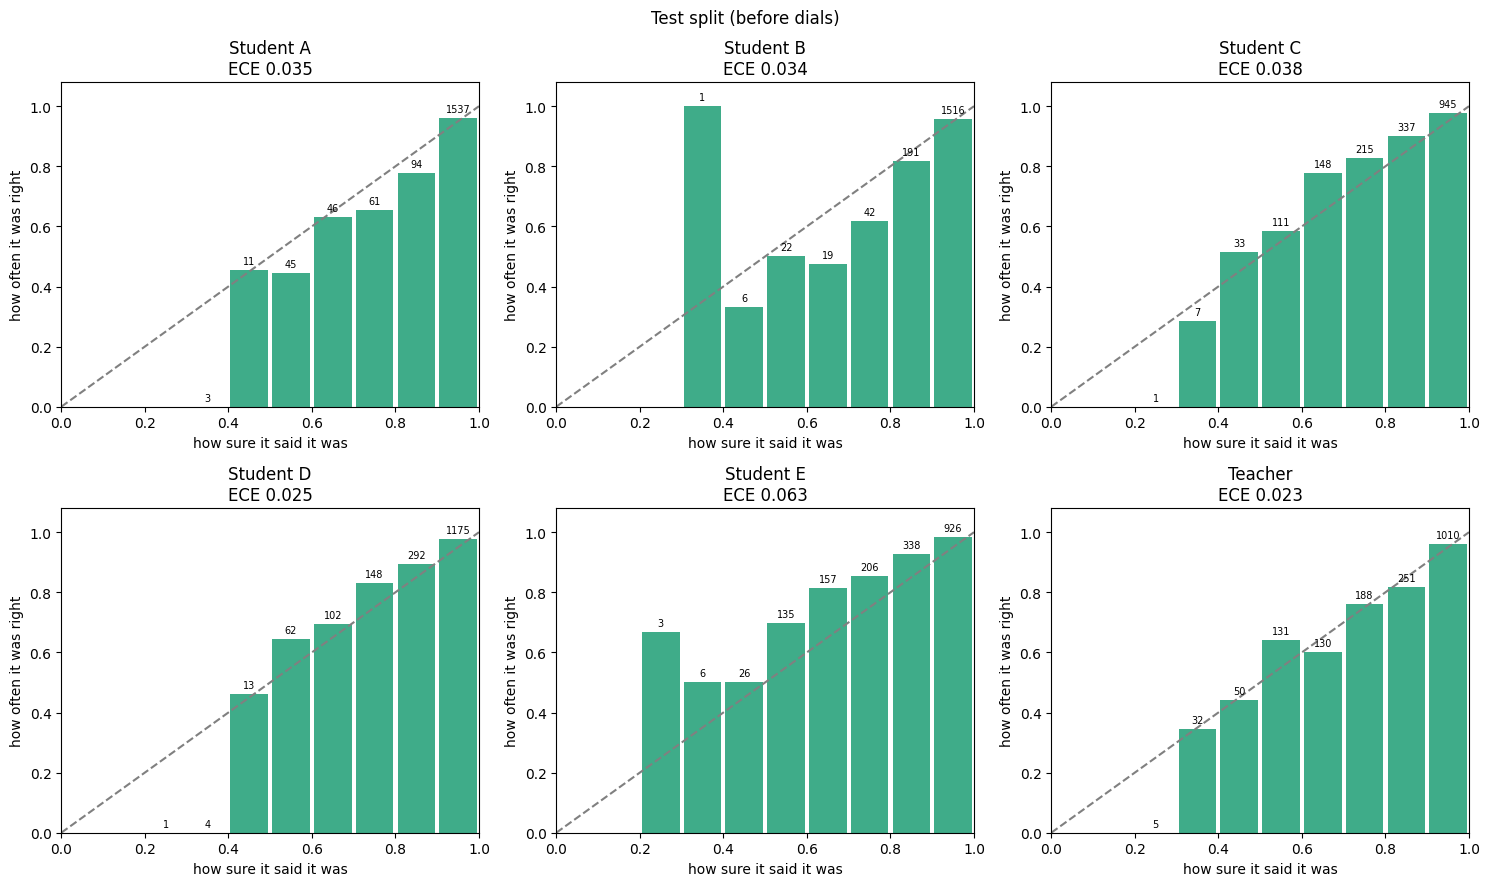

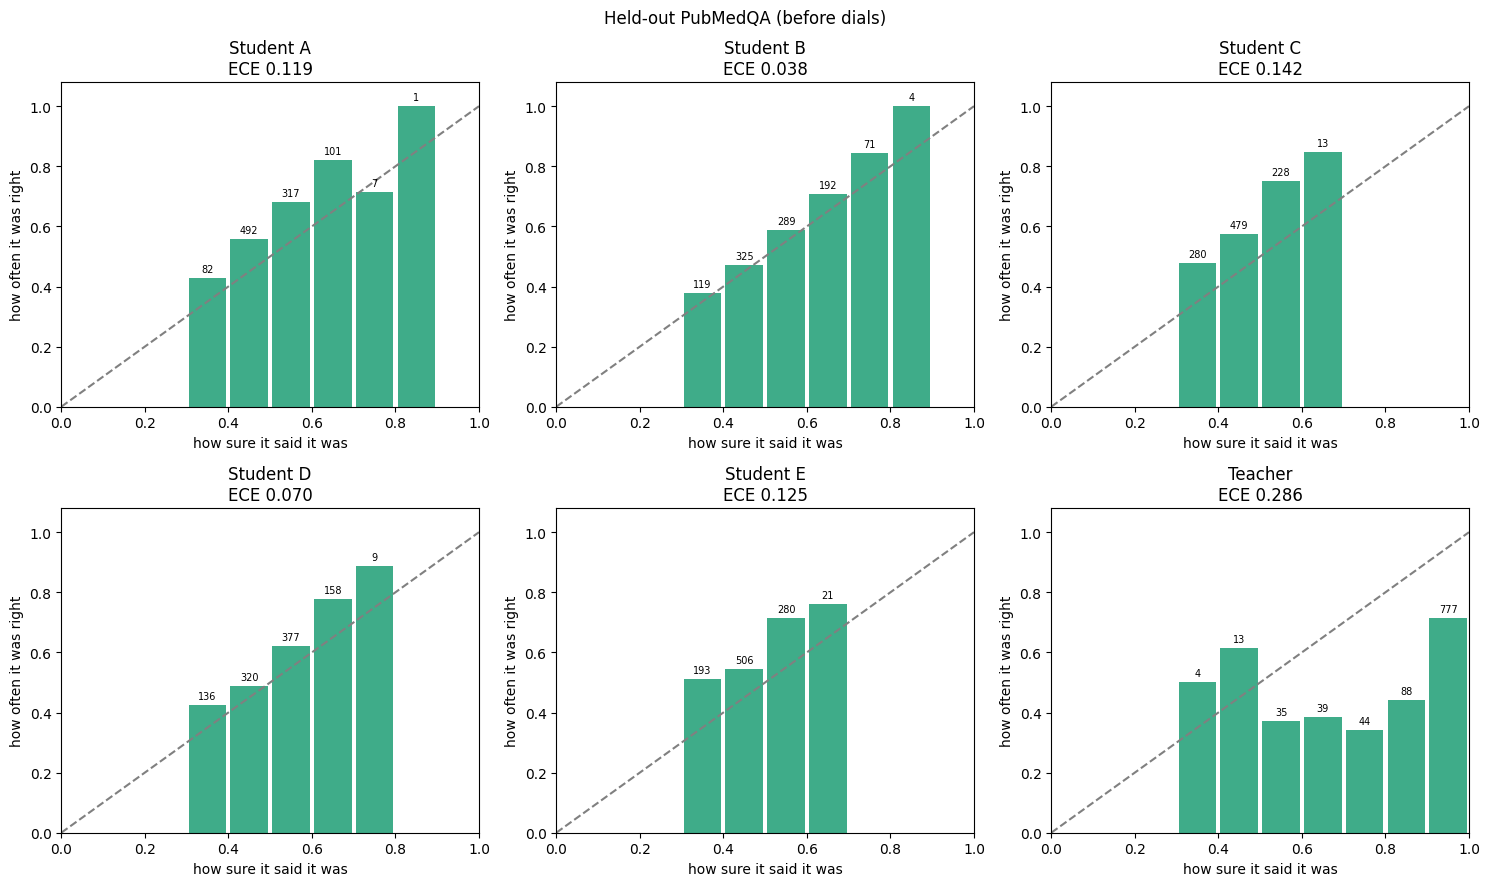

In [51]:
def reliability(ax, probs, rows, title):
    conf, correct, _ = per_row(probs, rows)
    bins = np.minimum((conf * N_BINS).astype(int), N_BINS - 1)
    for b in range(N_BINS):
        m = bins == b
        if m.any():
            center = (b + 0.5) / N_BINS
            ax.bar(center, correct[m].mean(), width=0.9 / N_BINS, color="#1D9E75", alpha=0.85)
            ax.text(center, correct[m].mean() + 0.02, str(int(m.sum())), ha="center", fontsize=7)
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(xlim=(0, 1), ylim=(0, 1.08), xlabel="how sure it said it was", ylabel="how often it was right",
           title=f"{title}\nECE {ece_from(conf, correct):.3f}")

def reliability_grid(P, rows, title, path):
    panels = [f"Student {r}" for r in RUNS] + ["Teacher"]
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, name in zip(axes.flat, panels):
        reliability(ax, P[name], rows, name)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()

reliability_grid(PROBS, TEST, "Test split (before dials)", f"{OUT_DIR}/reliability_test.png")
reliability_grid(PROBS_H, HELD, "Held-out PubMedQA (before dials)", f"{OUT_DIR}/reliability_heldout.png")

## **[20] — Training curves**

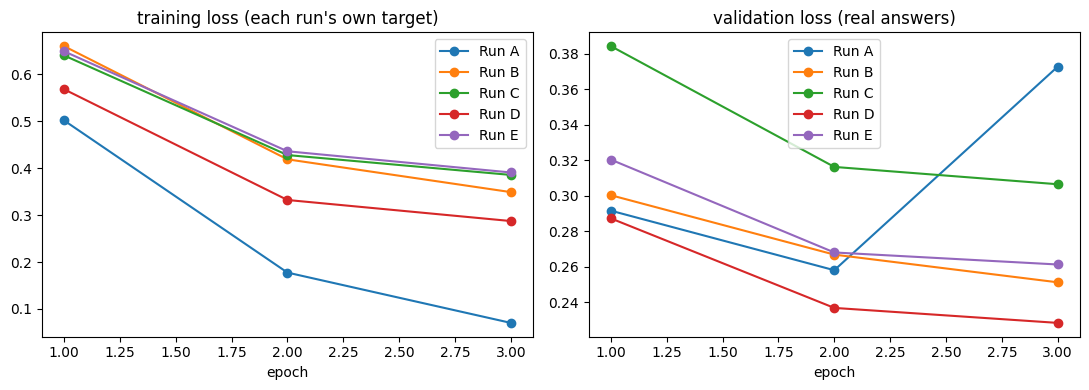

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for run in RUNS:
    h = pd.DataFrame(PREDS[run]["history"])
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", label=f"Run {run}")
    axes[1].plot(h["epoch"], h["val_loss"],   marker="o", label=f"Run {run}")
axes[0].set(title="training loss (each run's own target)", xlabel="epoch")
axes[1].set(title="validation loss (real answers)", xlabel="epoch")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=150)
plt.show()

## **[21] — (Optional): install Laya**

In [ ]:
!pip install -q laya

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.0/113.0 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.5/380.5 kB 17.6 MB/s eta 0:00:00


## **[22] — (Optional): Laya as an outside reference**

In [ ]:
from laya import Router
router = Router()

def laya_chances(row):
    if row["type"] == "noul":
        q = {"d": {"type": "noul", "instructions": row["instructions"]}}
    else:
        q = {"d": {"type": "choice", "instructions": row["instructions"],
                   "criteria": {o: o for o in row["options"]}}}
    ans = router.predict(row["state"], q)["answers"]["d"]
    if row["type"] == "noul":
        p_true = ans.get("probability", ans.get("value"))
        if p_true is None:
            raise KeyError(f"Couldn't find the yes/no probability in Laya's answer: {ans}")
        return np.array([1.0 - float(p_true), float(p_true)])
    p = np.array([float(ans["probabilities"].get(o, 0.0)) for o in row["options"]])
    if p.sum() == 0:
        raise KeyError(f"Laya's option names didn't match: {ans}")
    return p / p.sum()

t0 = time.time()
PROBS["Laya"] = [laya_chances(r) for r in TEST]
print(f"Laya scored {len(TEST)} test questions in {time.time() - t0:.0f}s")
print({k: round(float(v), 3) for k, v in metrics(PROBS["Laya"], TEST).items()})

## **[23] — Step 1: how many dials?**

In [ ]:
# Needs only: Cells 1-5, 13 and 15 (predictions loaded from Drive). No GPU, no retraining.
SCHEMES = ["no dial", "12 dials", "2 dials"]
REPEATS = 3                                   # random halvings of validation
GRID    = np.exp(np.linspace(np.log(0.25), np.log(20.0), 200))   # same search range as Cell 16
B_GRID  = np.linspace(-8.0, 8.0, 321)
VAL, TEST, HELD = DATA["validation"], DATA["test"], DATA["heldout"]

# 0. Saved predictions must line up with today's dataset rows
for run in RUNS:
    for split in ("validation", "test", "heldout"):
        assert len(PREDS[run][split]) == len(DATA[split]), f"{run}/{split}: row count differs"
        assert all(len(s) == len(r["options"]) for s, r in zip(PREDS[run][split], DATA[split]))
print("saved predictions line up with the dataset rows")

def group_of(row):
    return (row["source"], row["type"])

def fit_one(scores, rows):
    # One dial (and nudge for yes/no) with the lowest log loss on these rows
    y = np.array([r["gold_index"] for r in rows])
    if rows[0]["type"] == "noul":
        gap = np.array([s[1] - s[0] for s in scores])
        with np.errstate(over="ignore"):
            z = gap[None, None, :] / GRID[:, None, None] + B_GRID[None, :, None]
            p = 1.0 / (1.0 + np.exp(-z))
        pen = -(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)).mean(axis=2)
        i, j = np.unravel_index(np.argmin(pen), pen.shape)
        return float(GRID[i]), float(B_GRID[j])
    total = np.zeros(len(GRID))                 # choice: all 200 dial values at once
    by_k = {}
    for s, g in zip(scores, y):
        by_k.setdefault(len(s), []).append((s, g))
    for items in by_k.values():                 # questions with the same number of options together
        S = np.array([s for s, _ in items], dtype=float)
        g = np.array([g for _, g in items])
        Z = S[None] / GRID[:, None, None]
        Z = Z - Z.max(axis=2, keepdims=True)
        logp = Z - np.log(np.exp(Z).sum(axis=2, keepdims=True))
        total += -logp[:, np.arange(len(g)), g].sum(axis=1)
    return float(GRID[int(np.argmin(total))]), 0.0

def fit_scheme(scores, rows, scheme):
    # Returns (per-group dials, per-type dials). Groups without their own dial use the per-type one.
    if scheme == "no dial":
        return {}, {"choice": (1.0, 0.0), "noul": (1.0, 0.0)}
    pooled = {}
    for qtype in ("choice", "noul"):
        idx = [i for i, r in enumerate(rows) if r["type"] == qtype]
        pooled[qtype] = (fit_one([scores[i] for i in idx], [rows[i] for i in idx])
                         if len(idx) >= MIN_FIT_ROWS else (1.0, 0.0))
    if scheme == "2 dials":
        return {}, pooled
    dials = {}
    for g in {group_of(r) for r in rows}:
        idx = [i for i, r in enumerate(rows) if group_of(r) == g]
        if len(idx) >= MIN_FIT_ROWS:
            dials[g] = fit_one([scores[i] for i in idx], [rows[i] for i in idx])
    return dials, pooled

def apply_scheme(scores, rows, fitted):
    dials, pooled = fitted
    out = []
    for s, r in zip(scores, rows):
        T, b = dials.get(group_of(r), pooled[r["type"]])
        z = np.array(s, dtype=float) / T
        if r["type"] == "noul":
            z[1] += b
        out.append(softmax_np(z))
    return out

# 1. THE DECISION: cross-fitting on validation (fit on one half, score on the other)
cv = []
for run in RUNS:
    sv = PREDS[run]["validation"]
    for scheme in SCHEMES:
        lls, eces = [], []
        for rep in range(REPEATS):
            order = np.random.default_rng(SEED + rep).permutation(len(VAL))
            h1, h2 = order[: len(VAL) // 2], order[len(VAL) // 2:]
            for fit_idx, score_idx in ((h1, h2), (h2, h1)):
                fitted = fit_scheme([sv[i] for i in fit_idx], [VAL[i] for i in fit_idx], scheme)
                rows = [VAL[i] for i in score_idx]
                m = metrics(apply_scheme([sv[i] for i in score_idx], rows, fitted), rows)
                lls.append(m["log loss"])
                eces.append(m["ECE"])
        cv.append({"student": run, "dials": scheme, "log loss": np.mean(lls), "ECE": np.mean(eces)})
cv = pd.DataFrame(cv)
print("\nDECISION (validation, cross-fitted): lower is better")
display(cv.pivot(index="student", columns="dials", values="log loss")[SCHEMES].round(4)
          .rename(columns=lambda c: f"log loss: {c}"))
display(cv.pivot(index="student", columns="dials", values="ECE")[SCHEMES].round(4)
          .rename(columns=lambda c: f"ECE: {c}"))
avg = cv.groupby("dials")["log loss"].mean()[SCHEMES]
CHOSEN = avg.idxmin()
print("average validation log loss over all five students:", {k: round(float(v), 4) for k, v in avg.items()})
print("best setup per student:", cv.loc[cv.groupby("student")["log loss"].idxmin()].set_index("student")["dials"].to_dict())
print(f"\n=> chosen for every later step: {CHOSEN}")

# 2. THE REPORT: each setup fitted on ALL of validation, scored once on test and held-out
rep_rows = []
for run in RUNS:
    for scheme in SCHEMES:
        fitted = fit_scheme(PREDS[run]["validation"], VAL, scheme)
        mt = metrics(apply_scheme(PREDS[run]["test"], TEST, fitted), TEST)
        mh = metrics(apply_scheme(PREDS[run]["heldout"], HELD, fitted), HELD)
        rep_rows.append({"student": run, "dials": scheme,
                         "test acc": mt["accuracy"], "test ECE": mt["ECE"], "test log loss": mt["log loss"],
                         "held-out acc": mh["accuracy"], "held-out ECE": mh["ECE"], "held-out log loss": mh["log loss"]})
report = pd.DataFrame(rep_rows).round(3)
print("\nREPORT (test and held-out): for information, not for choosing")
display(report)

# 3. Correctness check: the 12-dial setup must reproduce Cell 17's "after dial" test numbers
CELL17 = {"A": (0.908, 0.018, 0.268), "B": (0.917, 0.025, 0.322), "C": (0.900, 0.019, 0.340),
          "D": (0.922, 0.015, 0.262), "E": (0.919, 0.016, 0.271)}
for run, expected in CELL17.items():
    got = tuple(round(float(x), 3) for x in
                report[(report["student"] == run) & (report["dials"] == "12 dials")][["test acc", "test ECE", "test log loss"]].values[0])
    ok = np.allclose(got, expected, atol=0.0015)
    print(f"12-dial check, Student {run}: {got} vs Cell 17 {expected} -> {'MATCH' if ok else 'DIFFERENT'}")

cv.to_csv(f"{OUT_DIR}/step1_dials_validation.csv", index=False)
report.to_csv(f"{OUT_DIR}/step1_dials_report.csv", index=False)

saved predictions line up with the dataset rows

DECISION (validation, cross-fitted): lower is better


dials,log loss: no dial,log loss: 12 dials,log loss: 2 dials
student,,,
A,0.2770,0.2686,0.2535
B,0.2469,0.2628,0.2373
C,0.3005,0.2756,0.2748
D,0.2254,0.2257,0.2175
E,0.2589,0.2275,0.2242


dials,ECE: no dial,ECE: 12 dials,ECE: 2 dials
student,,,
A,0.0391,0.0215,0.0185
B,0.0461,0.0150,0.0209
C,0.0497,0.0193,0.0186
D,0.0337,0.0174,0.0169
E,0.0718,0.0163,0.0178


average validation log loss over all five students: {'no dial': 0.2617, '12 dials': 0.2521, '2 dials': 0.2415}
best setup per student: {'A': '2 dials', 'B': '2 dials', 'C': '2 dials', 'D': '2 dials', 'E': '2 dials'}

=> chosen for every later step: 2 dials

REPORT (test and held-out): for information, not for choosing


,student,dials,test acc,test ECE,test log loss,held-out acc,held-out ECE,held-out log loss
0,A,no dial,0.910,0.039,0.298,0.538,0.049,0.977
1,A,12 dials,0.908,0.018,0.268,0.538,0.097,0.997
2,A,2 dials,0.909,0.019,0.267,0.538,0.097,0.997
3,B,no dial,0.918,0.035,0.291,0.585,0.066,0.943
4,B,12 dials,0.917,0.025,0.322,0.585,0.109,0.957
5,B,2 dials,0.918,0.025,0.289,0.585,0.109,0.957
6,C,no dial,0.896,0.046,0.323,0.580,0.071,0.954
7,C,12 dials,0.900,0.019,0.340,0.580,0.027,0.943
8,C,2 dials,0.898,0.020,0.307,0.580,0.027,0.943
9,D,no dial,0.920,0.026,0.247,0.548,0.090,1.021


12-dial check, Student A: (0.908, 0.018, 0.268) vs Cell 17 (0.908, 0.018, 0.268) -> MATCH
12-dial check, Student B: (0.917, 0.025, 0.322) vs Cell 17 (0.917, 0.025, 0.322) -> MATCH
12-dial check, Student C: (0.9, 0.019, 0.34) vs Cell 17 (0.9, 0.019, 0.34) -> MATCH
12-dial check, Student D: (0.922, 0.015, 0.262) vs Cell 17 (0.922, 0.015, 0.262) -> MATCH
12-dial check, Student E: (0.919, 0.016, 0.271) vs Cell 17 (0.919, 0.016, 0.271) -> MATCH


## **[24] — Results across seeds**

In [7]:
# Needs only: Cells 1-5 and 13. Loads every seed's predictions from Drive. No GPU.
def seed_dir(seed):
    return BASE_DIR if seed == 0 else f"{BASE_DIR}/seed{seed}"

ALL_PREDS = {}
for seed in SEEDS_ALL:
    for run in RUNS:
        path = f"{seed_dir(seed)}/preds_{run}.pkl"
        if os.path.exists(path):
            with open(path, "rb") as f:
                ALL_PREDS[seed, run] = pickle.load(f)
        else:
            print("not found yet:", path)
SEEDS_DONE = sorted({s for s, _ in ALL_PREDS})
assert all((s, r) in ALL_PREDS for s in SEEDS_DONE for r in RUNS), "each seed needs all five runs finished"
for (seed, run), P in ALL_PREDS.items():       # every saved prediction must line up with today's rows
    for split in ("validation", "test", "heldout"):
        assert len(P[split]) == len(DATA[split]), f"seed {seed}, run {run}, {split}: row count differs"
print("seeds found:", SEEDS_DONE)

# The 2-dial setup from Step 1 (same fitting as Cell 23)
GRID   = np.exp(np.linspace(np.log(0.25), np.log(20.0), 200))
B_GRID = np.linspace(-8.0, 8.0, 321)

def fit_one(scores, rows):
    y = np.array([r["gold_index"] for r in rows])
    if rows[0]["type"] == "noul":
        gap = np.array([s[1] - s[0] for s in scores])
        with np.errstate(over="ignore"):
            z = gap[None, None, :] / GRID[:, None, None] + B_GRID[None, :, None]
            p = 1.0 / (1.0 + np.exp(-z))
        pen = -(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)).mean(axis=2)
        i, j = np.unravel_index(np.argmin(pen), pen.shape)
        return float(GRID[i]), float(B_GRID[j])
    total, by_k = np.zeros(len(GRID)), {}
    for s, g in zip(scores, y):
        by_k.setdefault(len(s), []).append((s, g))
    for items in by_k.values():
        S = np.array([s for s, _ in items], dtype=float)
        g = np.array([g for _, g in items])
        Z = S[None] / GRID[:, None, None]
        Z = Z - Z.max(axis=2, keepdims=True)
        logp = Z - np.log(np.exp(Z).sum(axis=2, keepdims=True))
        total += -logp[:, np.arange(len(g)), g].sum(axis=1)
    return float(GRID[int(np.argmin(total))]), 0.0

def two_dials(scores, rows):
    pooled = {}
    for qtype in ("choice", "noul"):
        idx = [i for i, r in enumerate(rows) if r["type"] == qtype]
        pooled[qtype] = (fit_one([scores[i] for i in idx], [rows[i] for i in idx])
                         if len(idx) >= MIN_FIT_ROWS else (1.0, 0.0))
    return pooled

def apply_two(scores, rows, pooled):
    out = []
    for s, r in zip(scores, rows):
        T, b = pooled[r["type"]]
        z = np.array(s, dtype=float) / T
        if r["type"] == "noul":
            z[1] += b
        out.append(softmax_np(z))
    return out

# Every student: fit its 2 dials on validation, score test and held-out
rows_out = []
for (seed, run), P in sorted(ALL_PREDS.items()):
    pooled = two_dials(P["validation"], DATA["validation"])
    for split in ("test", "heldout"):
        m = metrics(apply_two(P[split], DATA[split], pooled), DATA[split])
        rows_out.append({"seed": seed, "run": run, "split": split,
                         **{k: float(v) for k, v in m.items()}})
PER_SEED = pd.DataFrame(rows_out)
MEASURES = ["accuracy", "ECE", "log loss"]

# 1. Mean and range across seeds
def mean_range(x):
    return f"{x.mean():.3f}  ({x.min():.3f} to {x.max():.3f})"
summary = (PER_SEED.groupby(["split", "run"])
           .agg(**{m: (m, mean_range) for m in MEASURES}).reset_index())
print(f"\n1. MEAN (lowest to highest) across {len(SEEDS_DONE)} seeds, 2 dials")
display(summary)

# 2. How big is training luck? Each run's spread (highest minus lowest) across seeds
spread = PER_SEED.groupby(["split", "run"])[MEASURES].agg(lambda x: x.max() - x.min()).round(4).reset_index()
print("\n2. TRAINING LUCK: how much each run moved between seeds (highest minus lowest)")
display(spread)

# 3. Does each comparison hold in every seed?
lines = []
for split in ("test", "heldout"):
    for cand in ["C", "D", "E"]:
        for base in ["A", "B"]:
            for measure, lower_is_better in [("accuracy", False), ("ECE", True), ("log loss", True)]:
                gaps = []
                for seed in SEEDS_DONE:
                    pick = lambda r: PER_SEED[(PER_SEED.seed == seed) & (PER_SEED.run == r) &
                                              (PER_SEED.split == split)][measure].iloc[0]
                    c, o = pick(cand), pick(base)
                    gaps.append((o - c) if lower_is_better else (c - o))   # positive = candidate better
                gaps = np.array(gaps)
                wins = int((gaps > 0).sum())
                lines.append({"split": split, "comparison": f"{cand} vs {base}", "measure": measure,
                              "seeds where candidate better": f"{wins}/{len(gaps)}",
                              "average gap": round(float(gaps.mean()), 4),
                              "gap range": f"{gaps.min():+.4f} to {gaps.max():+.4f}",
                              "verdict": (f"{cand} better in every seed" if wins == len(gaps) else
                                          f"{cand} worse in every seed" if wins == 0 else "depends on the seed")})
CONSISTENCY = pd.DataFrame(lines)
print("\n3. CONSISTENCY: does each comparison hold in every seed? (positive gap = candidate better)")
display(CONSISTENCY)

# Which epoch each student kept
epochs = pd.DataFrame([{"seed": s, "run": r, "kept epoch": P["best_epoch"]} for (s, r), P in ALL_PREDS.items()])
print("\nkept epoch per student:")
display(epochs.pivot(index="seed", columns="run", values="kept epoch"))

PER_SEED.to_csv(f"{BASE_DIR}/step2_per_seed.csv", index=False)
CONSISTENCY.to_csv(f"{BASE_DIR}/step2_consistency.csv", index=False)

seeds found: [0, 1, 2]

1. MEAN (lowest to highest) across 3 seeds, 2 dials


,split,run,accuracy,ECE,log loss
0,heldout,A,0.580 (0.538 to 0.614),0.130 (0.097 to 0.171),0.970 (0.945 to 0.997)
1,heldout,B,0.579 (0.568 to 0.585),0.092 (0.020 to 0.149),0.987 (0.957 to 1.005)
2,heldout,C,0.583 (0.576 to 0.592),0.055 (0.027 to 0.106),0.940 (0.926 to 0.952)
3,heldout,D,0.574 (0.548 to 0.595),0.044 (0.028 to 0.064),0.947 (0.878 to 1.017)
4,heldout,E,0.596 (0.591 to 0.605),0.086 (0.048 to 0.107),0.935 (0.924 to 0.946)
5,test,A,0.912 (0.909 to 0.917),0.011 (0.006 to 0.019),0.247 (0.230 to 0.267)
6,test,B,0.918 (0.913 to 0.923),0.022 (0.016 to 0.026),0.281 (0.268 to 0.289)
7,test,C,0.892 (0.886 to 0.898),0.021 (0.020 to 0.023),0.310 (0.307 to 0.313)
8,test,D,0.915 (0.909 to 0.918),0.016 (0.015 to 0.019),0.248 (0.241 to 0.256)
9,test,E,0.912 (0.908 to 0.915),0.015 (0.014 to 0.016),0.261 (0.252 to 0.267)



2. TRAINING LUCK: how much each run moved between seeds (highest minus lowest)


,split,run,accuracy,ECE,log loss
0,heldout,A,0.0760,0.0738,0.0522
1,heldout,B,0.0170,0.1289,0.0476
2,heldout,C,0.0160,0.0790,0.0257
3,heldout,D,0.0470,0.0356,0.1386
4,heldout,E,0.0140,0.0586,0.0221
5,test,A,0.0078,0.0132,0.0372
6,test,B,0.0100,0.0101,0.0208
7,test,C,0.0117,0.0031,0.0058
8,test,D,0.0083,0.0040,0.0153
9,test,E,0.0078,0.0018,0.0150



3. CONSISTENCY: does each comparison hold in every seed? (positive gap = candidate better)


,split,comparison,measure,seeds where candidate better,average gap,gap range,verdict
0,test,C vs A,accuracy,0/3,-0.0195,-0.0250 to -0.0106,C worse in every seed
1,test,C vs A,ECE,0/3,-0.0100,-0.0177 to -0.0015,C worse in every seed
2,test,C vs A,log loss,0/3,-0.0635,-0.0806 to -0.0393,C worse in every seed
3,test,C vs B,accuracy,0/3,-0.0260,-0.0317 to -0.0195,C worse in every seed
4,test,C vs B,ECE,2/3,0.0010,-0.0073 to +0.0060,depends on the seed
5,test,C vs B,log loss,0/3,-0.0292,-0.0426 to -0.0176,C worse in every seed
6,test,D vs A,accuracy,2/3,0.0032,+0.0000 to +0.0089,depends on the seed
7,test,D vs A,ECE,1/3,-0.0051,-0.0131 to +0.0033,depends on the seed
8,test,D vs A,log loss,1/3,-0.0020,-0.0182 to +0.0266,depends on the seed
9,test,D vs B,accuracy,0/3,-0.0033,-0.0061 to +0.0000,D worse in every seed



kept epoch per student:


run,A,B,C,D,E
seed,,,,,
0,1,3,2,2,2
1,2,3,2,2,2
2,2,3,3,3,3
